# 01 · Data: labels, cleaning, split by car model

In [1]:
import os, sys
REPO_URL = "https://github.com/YUPWE/car-size.git"
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = "/content/drive/MyDrive/car-size"
    if not os.path.exists(ROOT):
        !git clone {REPO_URL} {ROOT}
    os.chdir(ROOT)
    !git pull -q
    !pip install -q imagehash==4.3.2
    os.environ["CARS_DATA_DIR"] = "/content/cars_data"
else:
    ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
    os.chdir(ROOT)
sys.path.insert(0, ROOT)
os.makedirs("results", exist_ok=True)
os.makedirs("weights", exist_ok=True)
QUICK = os.environ.get("QUICK", "0") == "1"
print("Working in", os.getcwd(), "| QUICK =", QUICK)

Mounted at /content/drive
Mounted at /content/drive
Working in /content/drive/MyDrive/car-size | QUICK = False
Working in /content/drive/MyDrive/car-size | QUICK = False


Saving a resized copy to data/cars_resized.zip so the next notebooks start fast ...
Saving a resized copy to data/cars_resized.zip so the next notebooks start fast ...
16185 images, 196 car models, 157 car families
label
small    10660
big       5525
Name: count, dtype: int64
16185 images, 196 car models, 157 car families
label
small    10660
big       5525
Name: count, dtype: int64


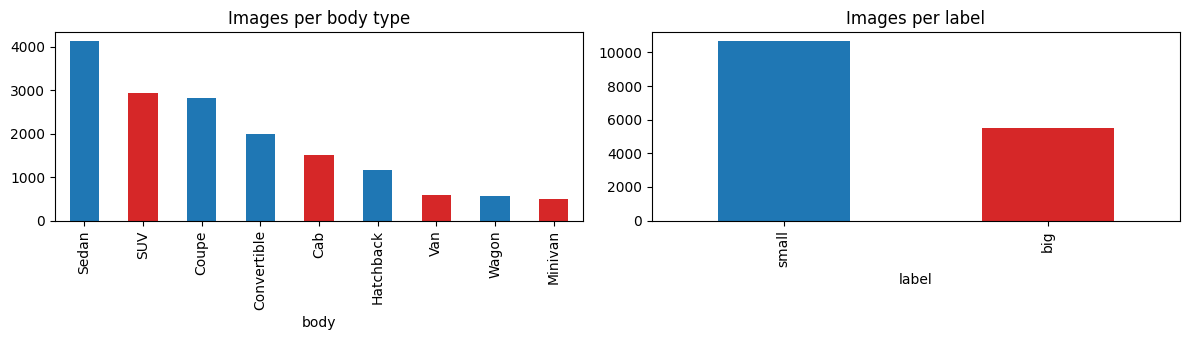

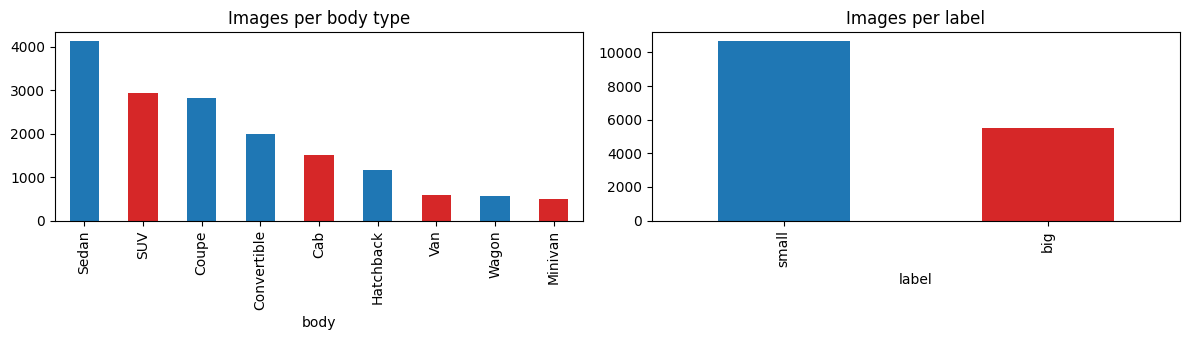

In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from PIL import Image
from src import data

data.download()
df = data.load_meta()
print(len(df), "images,", df.model.nunique(), "car models,", df.group.nunique(), "car families")
print(df.label.value_counts())

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
df.body.value_counts().plot.bar(ax=ax[0], title="Images per body type",
    color=["tab:red" if b in data.BIG_BODY else "tab:blue" for b in df.body.value_counts().index])
df.label.value_counts().plot.bar(ax=ax[1], title="Images per label", color=["tab:blue", "tab:red"])
plt.tight_layout(); plt.savefig("results/class_counts.png", dpi=120); plt.show()

In [3]:
models = df.drop_duplicates("model")[["model", "body", "label"]].sort_values("model")
print(models[models.model.isin(data.MANUAL_BODY)].to_string(index=False))
models.to_csv("results/model_labels.csv", index=False)

                                          model      body label
                      Acura Integra Type R 2001     Coupe small
                           Acura TL Type-S 2008     Sedan small
                            Buick Regal GS 2012     Sedan small
                       Chevrolet Cobalt SS 2010     Coupe small
Chevrolet Corvette Ron Fellows Edition Z06 2007     Coupe small
                    Chevrolet Corvette ZR1 2012     Coupe small
                          Chevrolet HHR SS 2010     Wagon small
                  Chevrolet TrailBlazer SS 2009       SUV   big
                        Chrysler 300 SRT-8 2010     Sedan small
                     Dodge Challenger SRT8 2011     Coupe small
                       Dodge Charger SRT-8 2009     Sedan small
                           FIAT 500 Abarth 2012 Hatchback small
                      Ford Ranger SuperCab 2011       Cab   big
                             Jaguar XK XKR 2012     Coupe small
Lamborghini Gallardo LP 570-4 Superlegge

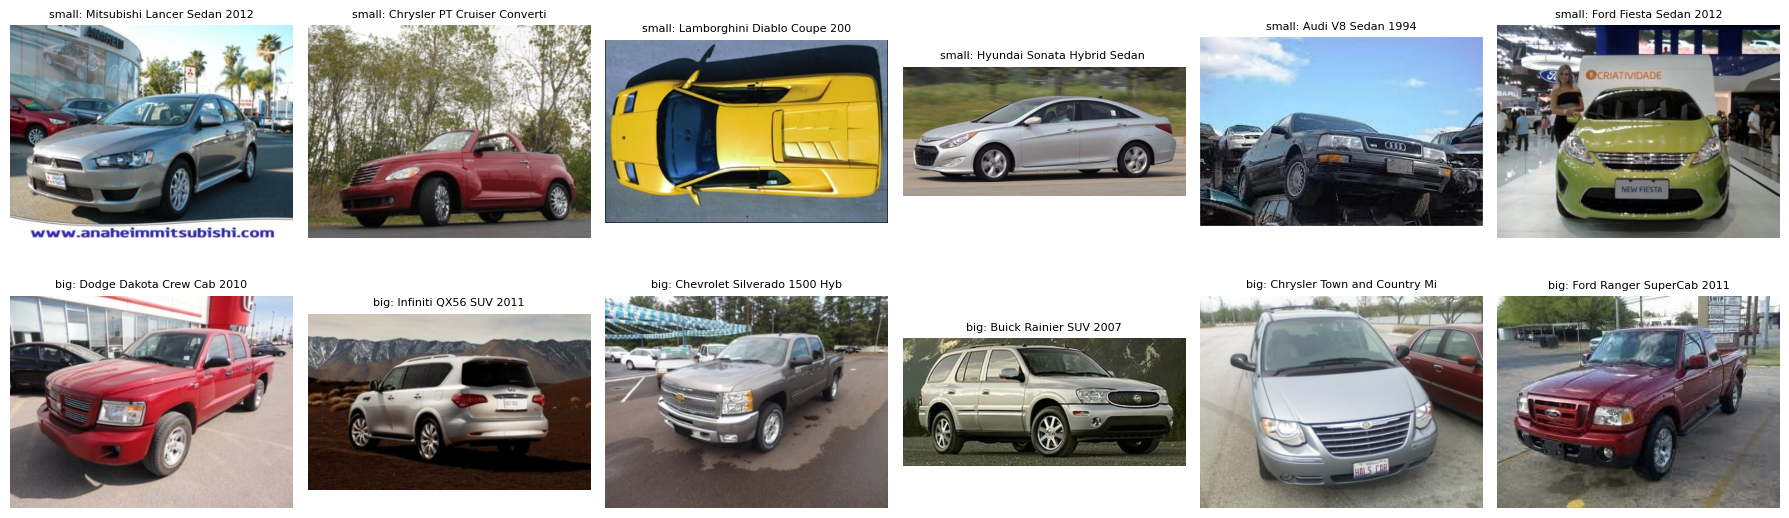

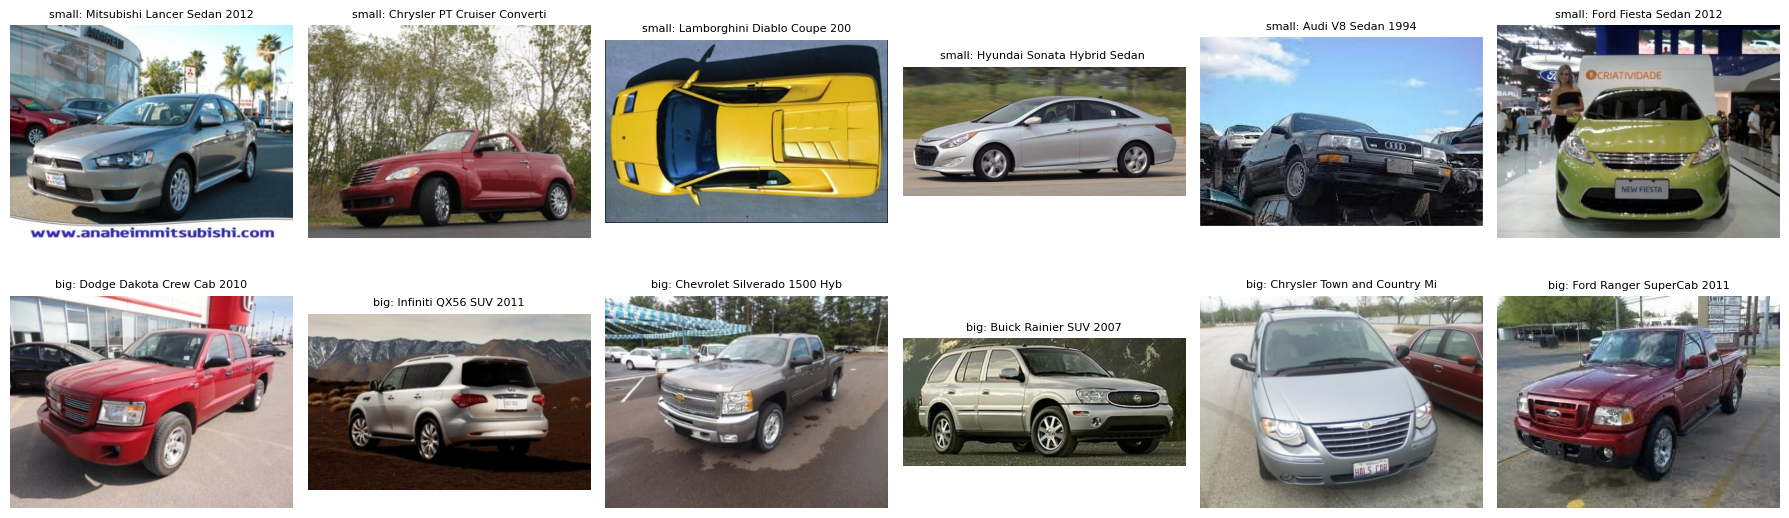

In [4]:
fig, axes = plt.subplots(2, 6, figsize=(18, 6))
for r, lab in enumerate(data.CLASSES):
    for k, (_, row) in enumerate(df[df.label == lab].sample(6, random_state=1).iterrows()):
        axes[r, k].imshow(Image.open(f"{data.IMG_DIR}/{row.path}")); axes[r, k].axis("off")
        axes[r, k].set_title(f"{lab}: {row.model[:28]}", fontsize=8)
plt.tight_layout(); plt.savefig("results/examples.png", dpi=100); plt.show()

## Cleaning

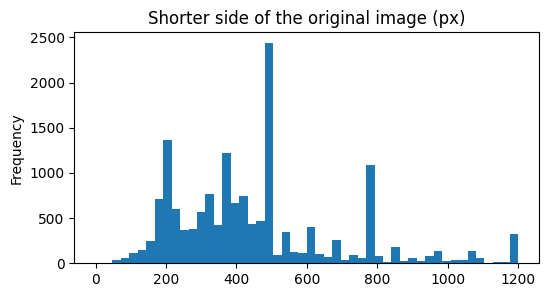

11 images with shorter side < 64 px; 284 under 128 px


In [5]:
short = df[["orig_w", "orig_h"]].min(axis=1)
short.plot.hist(bins=50, range=(0, 1200), figsize=(6, 3), title="Shorter side of the original image (px)"); plt.show()
tiny = df.index[short < 64]
print(len(tiny), "images with shorter side < 64 px;", (short < 128).sum(), "under 128 px")

61 near-duplicate pairs; 35 of them across different car families


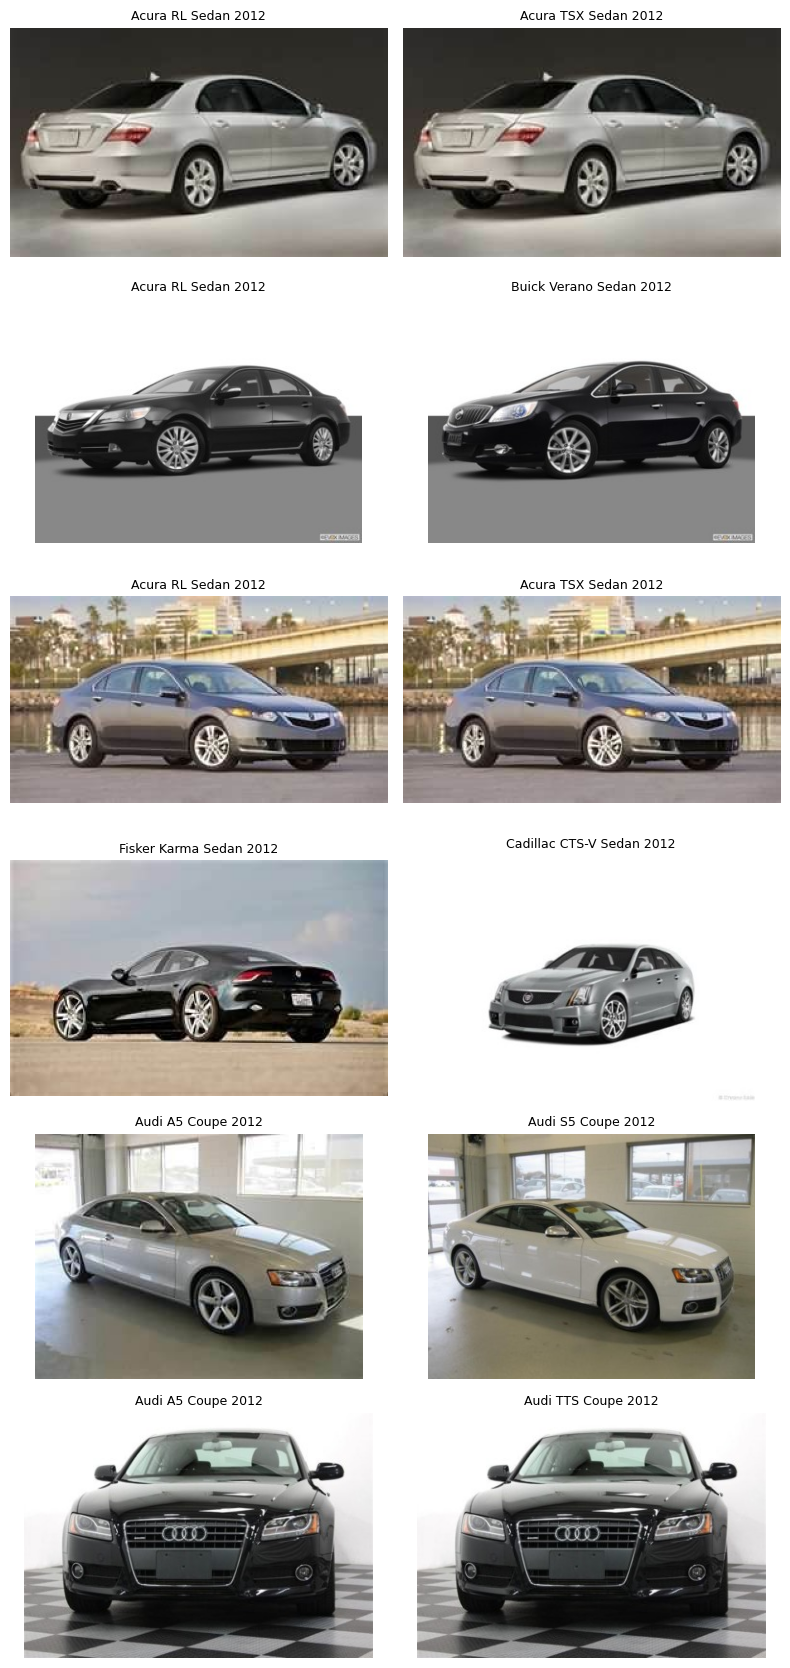

In [6]:
hashes = data.perceptual_hashes(df.path)
pairs = data.near_duplicate_pairs(hashes, max_dist=4)
cross = [(i, j) for i, j in pairs if df.group[i] != df.group[j]]
print(len(pairs), "near-duplicate pairs;", len(cross), "of them across different car families")

show = cross[:6]
fig, axes = plt.subplots(len(show), 2, figsize=(8, 2.8 * len(show)), squeeze=False)
for r, (i, j) in enumerate(show):
    for k, idx in enumerate([i, j]):
        axes[r, k].imshow(Image.open(f"{data.IMG_DIR}/{df.path[idx]}")); axes[r, k].axis("off")
        axes[r, k].set_title(df.model[idx], fontsize=9)
plt.tight_layout(); plt.savefig("results/duplicates_across_models.png", dpi=100); plt.show()

In [7]:
drop = sorted(set(tiny) | {k for p in cross for k in p})
clean = df.drop(index=drop).reset_index(drop=True)
print(f"Dropped {len(drop)} images -> {len(clean)} remain")

Dropped 81 images -> 16104 remain
Dropped 81 images -> 16104 remain


## Split by car family

In [8]:
split_df = data.make_splits(clean, seed=42)
print(pd.crosstab(split_df.label, split_df.split)[["train", "val", "test"]])
print(split_df.split.value_counts(normalize=True).round(3))
print("\nbig share per split:", split_df.groupby("split").label.apply(lambda s: round((s == "big").mean(), 3)).to_dict())

assert (split_df.groupby("group").split.nunique() == 1).all(), "a car family is in two splits!"
assert (split_df.groupby("model").split.nunique() == 1).all()
print("OK: no car family appears in two splits")
print("\nTest car families:", sorted(split_df[split_df.split == "test"].group.unique()))

split  train   val  test
label                   
big     4180   771   553
small   7431  1533  1636
split
train    0.721
val      0.143
test     0.136
Name: proportion, dtype: float64

big share per split: {'test': 0.253, 'train': 0.36, 'val': 0.335}
OK: no car family appears in two splits

Test car families: ['Audi A5', 'BMW M3', 'BMW M6', 'Bentley Continental', 'Chevrolet Express', 'Chevrolet Sonic', 'Chrysler Aspen', 'Chrysler Sebring', 'Dodge Challenger', 'Dodge Journey', 'FIAT 500', 'Ford F-450', 'Hyundai Tucson', 'Mercedes-Benz 300-Class', 'Mercedes-Benz S-Class', 'Nissan Juke', 'Ram C/V', 'Scion xD', 'Suzuki Aerio', 'Volkswagen Golf', 'Volvo 240']


In [9]:
data.save_splits(split_df)
print(os.listdir("splits"))

['.gitkeep', 'train.csv', 'val.csv', 'test.csv']
['.gitkeep', 'train.csv', 'val.csv', 'test.csv']


### Known problems found